# 1. Quickstart: models, files, photons, and observing them with XRISALIS

xrimodel describes a source as a set of **layers** on the sky, each with its own spectrum, spatial grid and time behaviour, and stores them in an **extended SIMPUT** FITS file. A simulator such as XRISALIS then only needs `xrimodel.format` to read the file and sample photons (time, position, energy).

In this notebook we first build a small scene with the engine, look at its per-pixel maps, write and read the file, sample a day of photons and measure the reverberation lag of a disc line behind its driving corona. We then build a model by hand, without the engine at all. In the second half we take a model through the X-ray interferometer simulator XRISALIS, from photons all the way to a reconstructed image. The later notebooks do the same for each of their models, using a short helper (`xri_helpers.observe`) that wraps these steps, so it is worth following them here once.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from astropy.io import fits
from matplotlib.colors import LogNorm

import xrimodel as xm
from xrimodel.engine import GaussianBlob, PointSource, Scene, ThinDisc


def extent(g):
    # imshow extent for a RegularGrid, East to the left
    return [g.x0 + g.nx / 2 * g.scale, g.x0 - g.nx / 2 * g.scale,
            g.y0 - g.ny / 2 * g.scale, g.y0 + g.ny / 2 * g.scale]

## A scene

We start with a Sgr A*-like geometry (1 r_g ≈ 5 µas at 8.2 kpc for 4.3×10⁶ M☉):

* a point-like **corona** (power law) whose brightness follows a red-noise **driver** (a power spectrum realised with a fixed seed);
* a thin Keplerian **disc** emitting a narrow 6.4 keV line, lit by a lamp 10 r_g above the hole, so each pixel follows the same driver *delayed* by its light-travel time, and is Doppler and gravitationally shifted (map `G`);
* a soft thermal **blob** offset from the centre.

In [2]:
scene = Scene(ra=266.41683, dec=-29.00781, distance_pc=8178.0,
              grid=xm.RegularGrid(nx=160, ny=160, scale=1.5))   # 1.5 uas pixels

f = np.geomspace(1e-5, 2e-2, 400)
scene.add_driver(xm.PSDDriver(f, xm.broken_powerlaw_psd(f, rms=0.4, f_break=2e-4),
                              name="corona", seed=42))
scene.add(PointSource("corona", {"kind": "powerlaw", "gamma": 2.0, "norm": 2e-3}, driver="corona"))
scene.add(ThinDisc("fe_line", {"kind": "gaussian_line", "e0": 6.4, "sigma": 0.003}, flux=3e-4,
                   mass_msun=4.3e6, r_in=6, r_out=30, inclination=60, position_angle=30,
                   h_lamp=10, driver="corona"))
scene.add(GaussianBlob("hot_spot", {"kind": "blackbody", "kt": 0.25, "norm": 5e-4},
                       sigma=15.0, x=80.0, y=-60.0))
model = scene.render()
for layer in model.layers:
    print(f"{layer.name:9s} {layer.kind:9s} {layer.mean_photon_flux():.2e} photons/s/cm^2")

corona    separable 6.50e-03 photons/s/cm^2
fe_line   specmap   3.00e-04 photons/s/cm^2
hot_spot  separable 3.74e-04 photons/s/cm^2


## Per-pixel maps

The disc is a **SpecMap** layer: one rest-frame template plus a set of per-pixel planes. Here we show three of them: `NORM` is the photon flux per pixel, `G` the energy shift (E_obs = G E_rest: blue on the approaching side, red on the receding side and near the hole) and `DELAY` the light-travel delay after the corona. The inner 6 r_g are empty, and the outer edge of the disc (30 r_g) runs off the grid.

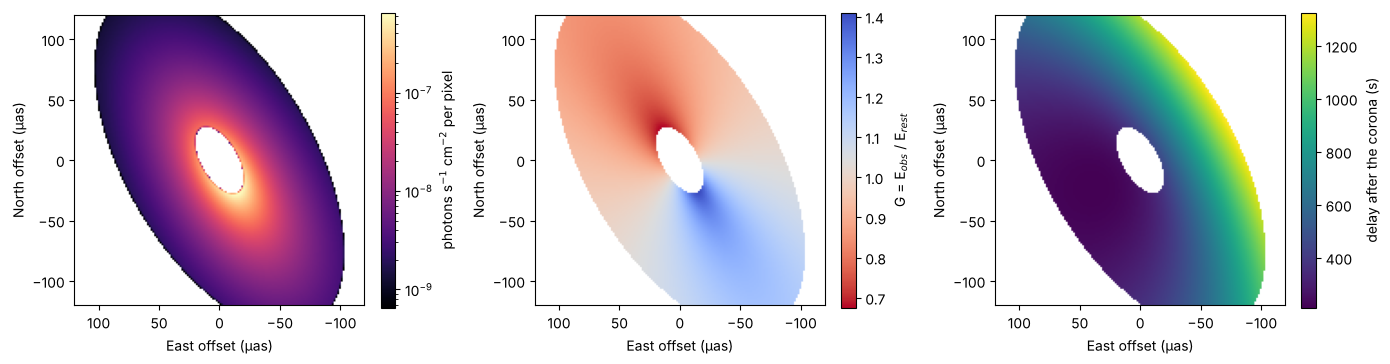

In [3]:
disc = model.layer("fe_line")
g = disc.grid
on = disc.maps["NORM"] > 0
fig, ax = plt.subplots(1, 3, figsize=(14, 4))
for a, (key, cmap, lab) in zip(ax, [("NORM", "magma", "photons s$^{-1}$ cm$^{-2}$ per pixel"),
                                    ("G", "coolwarm_r", "G = E$_{obs}$ / E$_{rest}$"),
                                    ("DELAY", "viridis", "delay after the corona (s)")]):
    img = g.to_image(np.where(on, disc.maps[key], np.nan))
    norm = LogNorm(vmin=img[on.reshape(img.shape)].max() * 1e-3) if key == "NORM" else None
    im = a.imshow(img, origin="lower", extent=extent(g), cmap=cmap, norm=norm)
    fig.colorbar(im, ax=a, label=lab, fraction=0.046)
    a.set_xlabel("East offset (µas)"); a.set_ylabel("North offset (µas)")
fig.tight_layout()

## The file

`write_model` writes the standard SIMPUT extensions (`SRC_CAT`, spectra, images), so any SIMPUT reader can use the file. Everything SIMPUT cannot hold goes into extra extensions: `SMAP_*` (the SpecMap planes), the driver definitions and the scene description (`MODELSPEC`), from which the whole scene can be rebuilt.

In [4]:
xm.write_model(model, "quickstart.fits", overwrite=True)
fits.info("quickstart.fits")
model = xm.read_model("quickstart.fits")
rebuilt = Scene.from_spec(model.spec)
print([c.name for c in rebuilt.components])

Filename: quickstart.fits
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  PRIMARY       1 PrimaryHDU       9   ()      
  1  SRC_CAT       1 BinTableHDU     54   3R x 16C   [J, 48A, D, D, E, E, E, E, E, 80A, 80A, 80A, 16A, 64A, D, D]   
  2  SPECTRUM      1 BinTableHDU     23   4R x 4C   [48A, PD(512), PD(512), PD(513)]   
  3  PSD_CORONA    1 BinTableHDU     21   400R x 2C   [D, D]   
  4  IMG_FE_LINE    1 ImageHDU        27   (160, 160)   float32   
  5  SMAP_FE_LINE    1 ImageHDU        42   (160, 160, 7)   float32   
  6  IMG_HOT_SPOT    1 ImageHDU        27   (160, 160)   float32   
  7  MODELSPEC     1 ImageHDU         8   (20821,)   uint8   


['corona', 'fe_line', 'hot_spot']


## Photons

Here we sample a day of photons on 100 cm² of effective area. Times come from thinning the driver (with each pixel's delay), energies from the templates shifted by `G`, and positions are drawn uniformly within each pixel.

61593 photons: {'corona': 55776, 'fe_line': 2605, 'hot_spot': 3212}


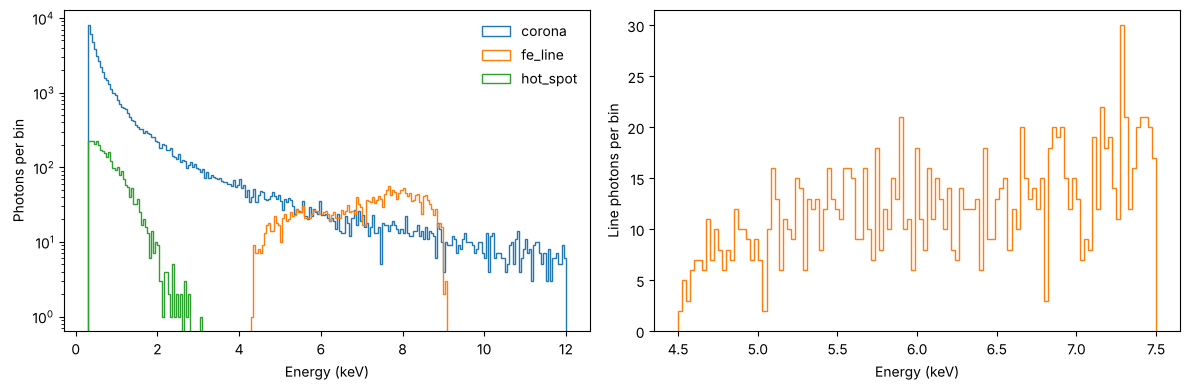

In [5]:
ph = xm.sample_photons(model, 0.0, 86400.0, area=100.0, rng=1)
print(len(ph), "photons:", {n: int((ph.layer == i).sum()) for i, n in enumerate(ph.layer_names)})

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
bins = np.linspace(0.3, 12, 235)
for i, name in enumerate(ph.layer_names):
    ax[0].hist(ph.energy[ph.layer == i], bins=bins, histtype="step", label=name)
ax[0].set_yscale("log"); ax[0].set_xlabel("Energy (keV)"); ax[0].set_ylabel("Photons per bin")
ax[0].legend(frameon=False)
fe = ph.layer == ph.layer_names.index("fe_line")
ax[1].hist(ph.energy[fe], bins=np.linspace(4.5, 7.5, 120), histtype="step", color="C1")
ax[1].set_xlabel("Energy (keV)"); ax[1].set_ylabel("Line photons per bin")
fig.tight_layout()

## Reverberation

The line follows the corona, delayed by the disc's light-travel times. The cross-correlation of the two light curves therefore peaks at the mean delay. `transfer_function` gives the full energy-delay response ψ(E, τ): the impulse response that spectral-timing codes (e.g. nDspec) turn into lag-energy spectra.

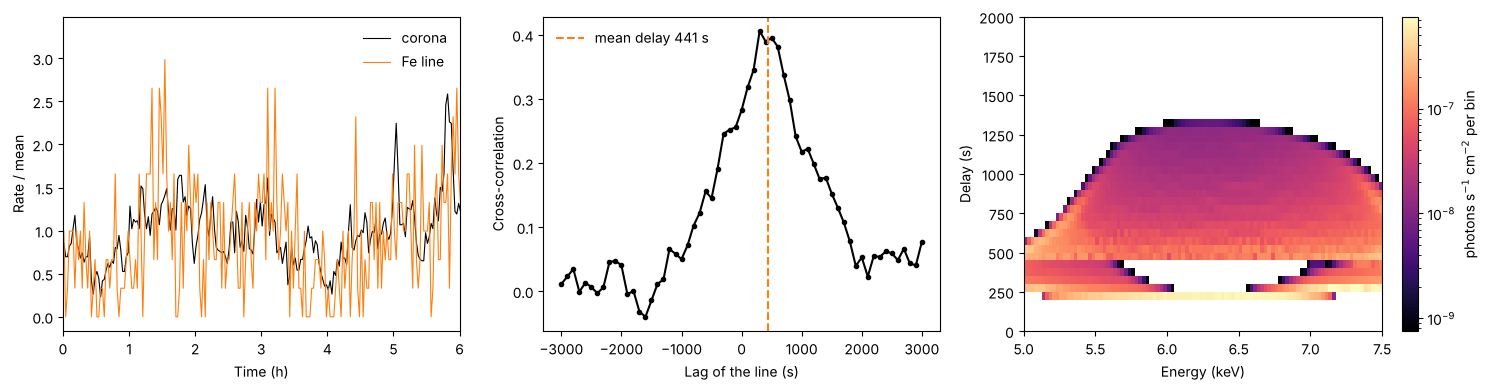

In [6]:
tb = np.arange(0.0, 86400.0 + 1, 100.0)
lc = {}
for name in ("corona", "fe_line"):
    lc[name], _ = np.histogram(ph.time[ph.layer == ph.layer_names.index(name)], tb)
a, b = (lc[k] - lc[k].mean() for k in ("corona", "fe_line"))
lags = np.arange(-30, 31)
cc = [np.corrcoef(a[max(0, -k):a.size - max(0, k)], b[max(0, k):b.size - max(0, -k)])[0, 1]
      for k in lags]
mean_delay = (disc.maps["NORM"] * disc.maps["DELAY"]).sum() / disc.maps["NORM"].sum()

e_edges = np.linspace(5.0, 7.5, 101)
d_edges = np.linspace(0.0, 2000.0, 41)
psi = xm.transfer_function(disc, e_edges, d_edges)

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
t = 0.5 * (tb[1:] + tb[:-1]) / 3600
ax[0].plot(t, lc["corona"] / lc["corona"].mean(), "k", lw=0.8, label="corona")
ax[0].plot(t, lc["fe_line"] / lc["fe_line"].mean(), "C1", lw=0.8, label="Fe line")
ax[0].set_xlim(0, 6); ax[0].set_xlabel("Time (h)"); ax[0].set_ylabel("Rate / mean")
ax[0].legend(frameon=False)
ax[1].plot(lags * 100.0, cc, "k.-")
ax[1].axvline(mean_delay, color="C1", ls="--", label=f"mean delay {mean_delay:.0f} s")
ax[1].set_xlabel("Lag of the line (s)"); ax[1].set_ylabel("Cross-correlation")
ax[1].legend(frameon=False)
im = ax[2].imshow(np.where(psi > 0, psi, np.nan).T, origin="lower", aspect="auto", cmap="magma",
                  norm=LogNorm(vmin=psi.max() * 1e-3),
                  extent=[e_edges[0], e_edges[-1], d_edges[0], d_edges[-1]])
fig.colorbar(im, ax=ax[2], label="photons s$^{-1}$ cm$^{-2}$ per bin", fraction=0.046)
ax[2].set_xlabel("Energy (keV)"); ax[2].set_ylabel("Delay (s)")
fig.tight_layout()

## A model by hand

The engine is entirely optional: any code can write layers directly. As an example, we make a ring whose energy shift varies with azimuth, next to a periodically varying point source. Pixels are tangent-plane offsets in µas (x East, y North) from the model's reference position.

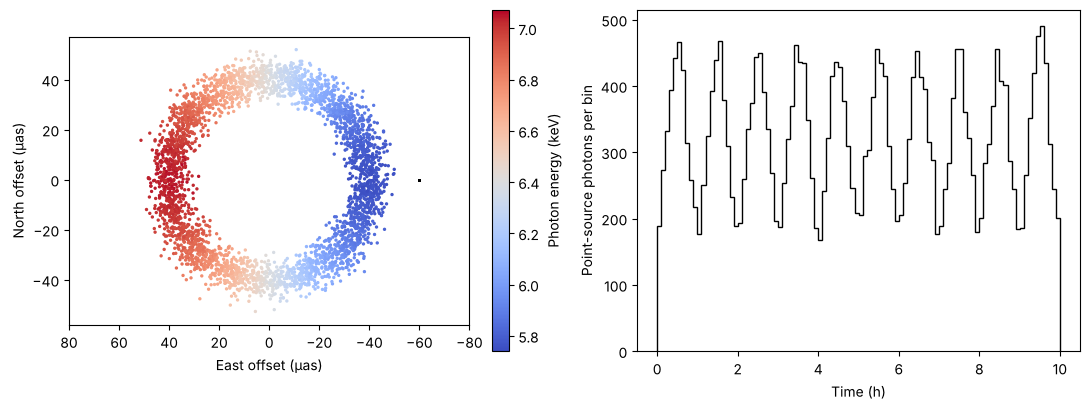

In [7]:
grid = xm.RegularGrid(nx=64, ny=64, scale=2.0)
x, y = grid.centres()
r, phi = np.hypot(x, y), np.arctan2(x, y)
ring = np.exp(-0.5 * ((r - 40.0) / 4.0) ** 2)
e = xm.energy_grid(1.0, 10.0, 0.01)

hand = xm.Model(ra=10.0, dec=-20.0)
hand.add_driver(xm.LightCurve([0.0, 0.5, 1.0], [0.5, 1.5, 0.5], name="orbit",
                              periodic=True, period=3600.0))
hand.add(xm.SeparableLayer("star", xm.powerlaw(e, 2.0, 1e-2), x=-60.0, y=0.0, driver="orbit"))
hand.add(xm.SpecMapLayer("ring", grid, [xm.gaussian_line(e, 6.4, 0.01)],
                         {"NORM": 1e-3 * ring / ring.sum(), "G": 1.0 + 0.1 * np.sin(phi)}))
xm.write_model(hand, "by_hand.fits", overwrite=True)

ph2 = xm.sample_photons(xm.read_model("by_hand.fits"), 0.0, 3.6e4, area=100.0, rng=2)
ringph = ph2.layer == ph2.layer_names.index("ring")
fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))
sc = ax[0].scatter(ph2.x[ringph], ph2.y[ringph], c=ph2.energy[ringph], s=2, cmap="coolwarm")
ax[0].plot(ph2.x[~ringph][:300], ph2.y[~ringph][:300], "k.", ms=2)
fig.colorbar(sc, ax=ax[0], label="Photon energy (keV)", fraction=0.046)
ax[0].set_xlim(80, -80); ax[0].set_aspect("equal")
ax[0].set_xlabel("East offset (µas)"); ax[0].set_ylabel("North offset (µas)")
ax[1].hist(ph2.time[~ringph] / 3600, bins=100, histtype="step", color="k")
ax[1].set_xlabel("Time (h)"); ax[1].set_ylabel("Point-source photons per bin")
fig.tight_layout()

---
# Observing a model with XRISALIS

The model generator and the simulator meet at the model itself: XRISALIS takes an xrimodel model as a source (`XrimodelSource`), draws its photons with xrimodel and assigns them to baselines according to the effective area (ARF). After that, the usual XRISALIS stages run: `generate_photons` → `redistribute` (energy response, fringe positions on the detector, attitude) → `reconstruct`.

The scene above is only ~100 µas across, smaller than the beam of the 10-baseline instrument bundled with XRISALIS (~190 µas). For this part we therefore use a target that the instrument resolves: a young active star (1 R☉ at 15 pc, so its disc is 620 µas across) with two bright active regions, coronal loops above them and a fainter quiet corona over the whole surface.

Needs XRISALIS (the `xrimodel-integration` branch or later).

In [8]:
import warnings
from importlib.resources import files

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import PowerNorm
from scipy.signal import fftconvolve

import xrimodel as xm
from xrimodel.engine import Loop, Scene, Sphere, System3D
import xrisalis as xs
from xrisalis.io import ARF, RMF

resp = files("xrisalis") / "data" / "responses"
arf, rmf = ARF.read(str(resp / "arf_10bl.fits")), RMF.read(str(resp / "rmf.fits"))

## The star

The surface emits uniformly (the quiet corona), plus two spots 10× brighter and 15° in radius. Above each spot a loop rises 0.15 R☉ (emissivity j0 in photons/s/cm³/sr, chosen so that a loop is about as bright as its spot). The star rotates (equatorial speed ~100 km/s) about an axis tilted 60° to the line of sight. For simplicity the spectra are a 1 keV blackbody, as a stand-in for a coronal plasma model (`{"kind": "xspec", "model": "C_apec", ...}` with xspectrampoline).

ab_loop0_emit0 2.47e-03 photons/s/cm^2
ab_loop1_emit0 2.86e-03 photons/s/cm^2
ab_star_emit 2.47e-02 photons/s/cm^2


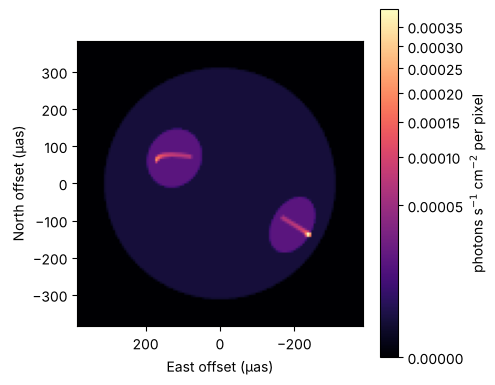

In [9]:
spec = {"kind": "blackbody", "kt": 1.0, "norm": 1.0}
rot = {"omega": 2 * np.pi / (0.5 * 86400), "axis": (0.0, 0.0, 1.0)}   # 0.5 d period
spots = [{"lat": 45, "lon": -60, "radius": 15, "intensity": 1.0},    # (the observer is at
         {"lat": -5, "lon": -125, "radius": 15, "intensity": 1.0}]   #  lat 30, lon -90)
star = Sphere(name="star", radius=1.0, rotation=rot, reflection=None,
              emission={"spectrum": spec, "intensity": 0.1, "spots": spots})
loops = [Loop(name=f"loop{k}", r_star=1.0, foot1=(s["lat"] - 8, s["lon"] - 8),
              foot2=(s["lat"] + 8, s["lon"] + 8), height=0.15, thickness=0.02, n0=1.0,
              rotation=rot, emission={"spectrum": spec, "j0": 2e-9}, n_fine=1024)
         for k, s in enumerate(spots)]
system = System3D(name="ab", length_unit="Rsun", inclination=60.0, node_pa=20.0,
                  bodies=[star], volumes=loops, supersample=3, chunk=1024)
grid = xm.RegularGrid(nx=128, ny=128, scale=6.0)                         # 6 uas pixels
scene = Scene(ra=82.1866, dec=-65.4498, distance_pc=15.0, grid=grid)     # AB Dor's position
scene.add(system)
model = scene.render()

# intensities above are relative (photons/s/cm^2/sr; loops ~ spots); scale the total to
# 0.03 photons/s/cm^2, an illustrative bright active star
total = sum(L.mean_photon_flux() for L in model.layers)
for L in model.layers:
    L.maps["NORM"] *= 0.03 / total
    print(f"{L.name:12s} {L.mean_photon_flux():.2e} photons/s/cm^2")

true = grid.to_image(sum(L.maps["NORM"] for L in model.layers))
h = grid.nx / 2 * grid.scale
fig, ax = plt.subplots(figsize=(5, 4.2))
im = ax.imshow(true, origin="lower", extent=[h, -h, -h, h], cmap="magma", norm=PowerNorm(0.4))
fig.colorbar(im, ax=ax, label="photons s$^{-1}$ cm$^{-2}$ per pixel")
ax.set_xlabel("East offset (µas)"); ax.set_ylabel("North offset (µas)")
fig.tight_layout()

## Simulate an observation

`XrimodelSource` returns photons at their absolute RA/Dec around the model's position, which is also the default pointing. The instrument rolls through half a turn over the exposure (`smooth_roll`), so every baseline is sampled at all position angles, as in a real observation with a rotating spacecraft.

We reconstruct from the **detected** energies, as one would with real data. Because the fringe spacing scales with energy, the detector's energy resolution smears the fringes, more so at high fringe orders (chromatic decoherence). `reconstruct`'s `deconvolve` option undoes this in the visibility domain, weighting each photon by its expected coherence for a detector resolving power `R = E/σ_E` (from the RMF, via `xs.resolving_power`). To have something to compare against, we also observe a reference point source at the same position in the same way, which gives us the instrument's point-spread function (the dirty beam).

In [10]:
exposure = 5000.0   # s
inst = xs.Interferometer.from_arf(arf, roller=xs.instrument.smooth_roll)
src = xs.XrimodelSource(model)
photons = xs.generate_photons(src, arf, exposure, seed=1)
events = xs.redistribute(photons, inst, rmf, seed=2)
print(f"{len(photons)} photons, {len(events)} events")

fov = 0.0012   # arcsec, 1200 uas
# detected energies, deconvolving the chromatic decoherence at the detector resolving power
# for the events' median energy
R = xs.resolving_power(rmf, np.median(events.energy_kev))
# 15 uas pixels: fine enough for the finest fringe, coarse enough to keep the IFFT small
samples = (80, 80)
img, span, _, meta = xs.reconstruct(events, inst, fov_arcsec=fov, deconvolve=R, samples=samples)

point = xm.Model(ra=model.ra, dec=model.dec)
point.add(xm.SeparableLayer("pt", xm.blackbody(xm.energy_grid(), 1.0, 1.0)))
point.layers[0].spectrum.values *= 0.03 / point.layers[0].mean_photon_flux()
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    ev_pt = xs.redistribute(xs.generate_photons(xs.XrimodelSource(point), arf, exposure, seed=3),
                            inst, rmf, seed=4)
psf, _, _, _ = xs.reconstruct(ev_pt, inst, fov_arcsec=fov, deconvolve=R, samples=samples)
fwhm = 2.3548 * xs.beam_sigma_uas(psf, span / psf.shape[0])
print(f"R = {R:.0f}; image span {span:.0f} uas, pixel {span / img.shape[0]:.1f} uas, beam FWHM ~{fwhm:.0f} uas")

167727 photons, 167727 events


R = 43; image span 1200 uas, pixel 15.0 uas, beam FWHM ~201 uas


## Compare

Here we show the true image on the reconstruction's pixel grid, the true image convolved with the dirty beam (what a perfect instrument with this uv coverage would show) and the reconstruction itself. All three panels use the same square-root-like stretch, so that the quiet corona over the whole disc shows. The beam (~200 µas) resolves the two active regions and the star's extent, but not the loops. The dirty beam is normalised to its peak rather than its sum: there are no zero-length baselines, so the total flux is never measured and the beam integrates to about zero.

Text(0, 0.5, 'North offset (µas)')

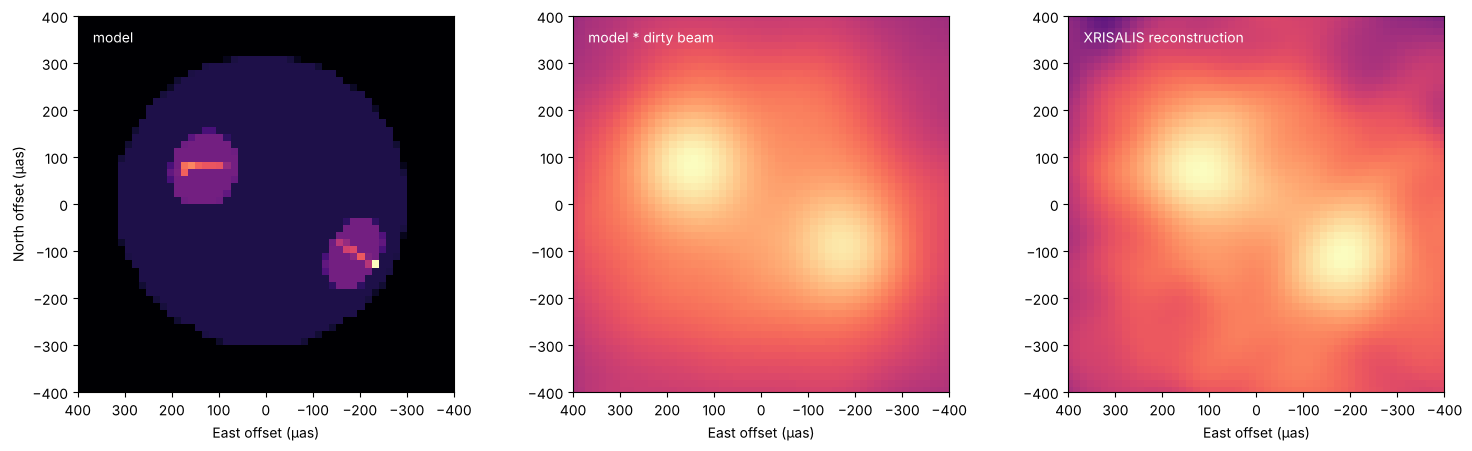

In [11]:
n = img.shape[0]
pix = span / n
c = (np.arange(n) - n / 2) * pix                     # reconstruction pixel centres (uas, East = +)
xc, yc = grid.centres()
# resample the model onto the reconstruction grid (nearest model pixel)
ix = np.clip(np.round((grid.nx / 2 - 0.5) - c / grid.scale).astype(int), 0, grid.nx - 1)
iy = np.clip(np.round(c / grid.scale + grid.ny / 2 - 0.5).astype(int), 0, grid.ny - 1)
true_r = true[np.ix_(iy, ix)]
conv = fftconvolve(true_r, psf / psf.max(), mode="same")   # (the beam integrates to ~0)

fig, ax = plt.subplots(1, 3, figsize=(15, 4.4), constrained_layout=True)
hr = span / 2
for a, im_, lab in [(ax[0], true_r, "model"), (ax[1], conv, "model * dirty beam"),
                    (ax[2], img, "XRISALIS reconstruction")]:
    a.imshow(np.clip(im_ / im_.max(), 0, None), origin="lower", extent=[-hr, hr, -hr, hr],
             cmap="magma", norm=PowerNorm(0.4, vmin=0, vmax=1))
    a.invert_xaxis()
    a.set_xlim(400, -400); a.set_ylim(-400, 400)
    a.text(0.04, 0.93, lab, transform=a.transAxes, color="w")
    a.set_xlabel("East offset (µas)")
ax[0].set_ylabel("North offset (µas)")

## How the roll samples the uv plane

Each baseline of length B measures the visibility at one spatial frequency, |u| = B/λ. Rolling the spacecraft through half a turn sweeps that frequency through all position angles (half a turn is enough, since the visibility at −u is the complex conjugate of the one at +u), so each baseline traces a circle in the uv plane. The roll therefore fills in the *angle*, but not the *radius*: with a fixed set of baseline lengths, what fills the gaps between them is the bandwidth.

Here we show the uv points actually sampled by two point sources, one emitting only a narrow 6.4 keV line and one a broad power law, and their dirty beams. In the bundled ARF only the shorter baselines have effective area at high energies (at 6.4 keV, essentially the four shortest), so the line gives four bright circles; the faint circles inside them are photons detected in the silicon escape peak, whose energy (and so assigned uv radius) is ~1.74 keV too low. The gaps between the circles give the beam strong ring sidelobes. For the continuum, each baseline covers B/λ over the whole band, the annuli of neighbouring baselines overlap, and the sidelobes wash out into a smooth, faint halo.

This is a property of the array rather than of the simulation: a real observation of a line-dominated source with these baselines would show the same rings. Removing them needs more baseline lengths, or deconvolution of the beam itself (e.g. CLEAN or forward modelling), which `reconstruct` does not do; its `deconvolve` only undoes the chromatic decoherence.

Text(0, 0.5, 'North offset (mas)')

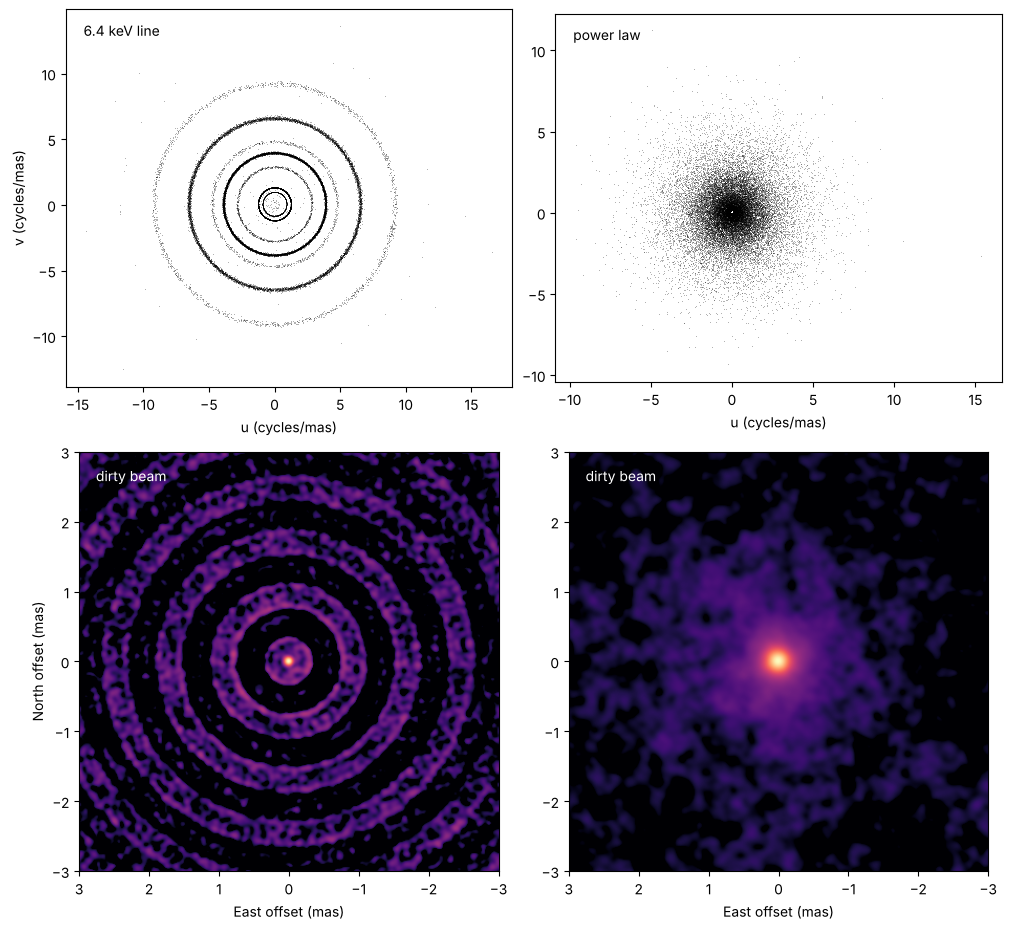

In [12]:
import xri_helpers as xri

edges = xm.energy_grid()
line_pt = xri.point_source_like(model, 0.05, spectrum=xm.gaussian_line(edges, 6.4, 0.01))
cont_pt = xri.point_source_like(model, 0.05, spectrum=xm.powerlaw(edges, 1.7))
beams = {lab: xri.observe(pt, exposure, 0.006, seed=7)
         for lab, pt in [("6.4 keV line", line_pt), ("power law", cont_pt)]}

MAS = np.pi / 180 / 3600e3                      # 1 mas in rad: uv in cycles per mas
fig, ax = plt.subplots(2, 2, figsize=(10, 9.4), constrained_layout=True)
rng = np.random.default_rng(0)
for k, (lab, obs) in enumerate(beams.items()):
    uv = obs["uv"] * MAS
    pick = rng.choice(len(uv), size=min(len(uv), 30000), replace=False)
    ax[0, k].plot(uv[pick, 0], uv[pick, 1], ",", color="k", alpha=0.3)
    ax[0, k].set_aspect("equal")
    ax[0, k].set_xlabel("u (cycles/mas)")
    ax[0, k].text(0.04, 0.93, lab, transform=ax[0, k].transAxes)
    xri.show(ax[1, k], dict(obs, image=obs["image"] / obs["image"].max()), unit=1e3, gamma=0.5,
             label="dirty beam")
ax[0, 0].set_ylabel("v (cycles/mas)")
ax[1, 0].set_ylabel("North offset (mas)")


## The same in one call, and the effect of the deconvolution

All of the steps above are wrapped in `xri_helpers.py` (next to these notebooks): `observe(model, exposure, fov_arcsec, total_flux=None, seed=0, **reconstruct_options)` simulates and reconstructs (by default from the detected energies with `deconvolve`, as above), returning the image, its span, the uv sampling and the events, and `show` plots a reconstruction. The later notebooks use these throughout.

As an example, we use it here to show what the deconvolution does. We compare the reconstruction from the photons' **true** energies (an ideal detector; `use_true_energy=True` is a diagnostic only), from the **detected** energies without any correction, and from the detected energies with `deconvolve` (the default). Without the correction the high-order fringes decohere and the image loses its structure in noise; the deconvolution recovers most of it.

Text(0, 0.5, 'North offset (µas)')

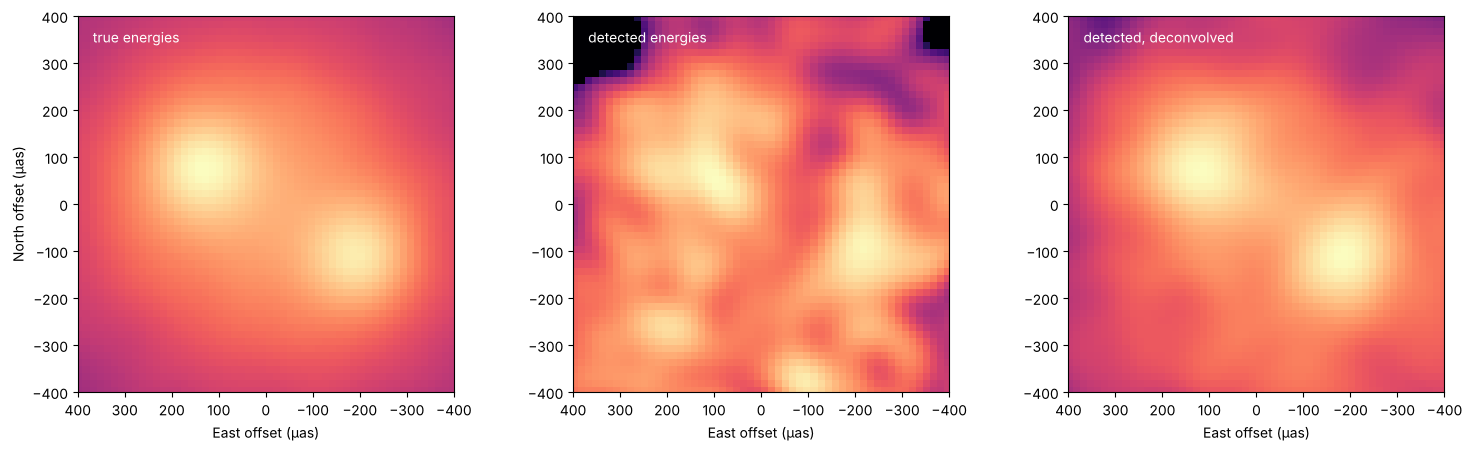

In [13]:
true_e = xri.observe(model, exposure, fov, seed=1, use_true_energy=True)
raw = xri.observe(model, exposure, fov, seed=1, deconvolve=None)
deconv = xri.observe(model, exposure, fov, seed=1)
fig, ax = plt.subplots(1, 3, figsize=(15, 4.4), constrained_layout=True)
xri.show(ax[0], true_e, lim=400, gamma=0.4, label="true energies")
xri.show(ax[1], raw, lim=400, gamma=0.4, label="detected energies")
xri.show(ax[2], deconv, lim=400, gamma=0.4, label="detected, deconvolved")
ax[0].set_ylabel("North offset (µas)")